# 03_1 — Modélisation : comparaison de plusieurs algorithmes

**Projet 6 OpenClassrooms — Modèle de scoring crédit « Prêt à dépenser »**

**Étape 3 des consignes : « Modélisez et expérimentez avec plusieurs algorithmes »**. Résultat attendu : plusieurs modèles entraînés, avec validation croisée et premières métriques d'évaluation, tracés dans MLflow.

**Démarche**
1. Définir le **coût métier** (FN = 10 × FP) et la recherche du **seuil de décision** qui le minimise.
2. Évaluer chaque modèle en **`StratifiedKFold` à 5 plis**, avec ses hyperparamètres par défaut (ou presque) : on compare des familles de modèles, pas des réglages fins.
3. Gérer le **déséquilibre** (8 % de défauts) : `class_weight`, `scale_pos_weight`, sous-échantillonnage ou SMOTE, **toujours à l'intérieur des plis**.
4. Tracer **un run MLflow par modèle** : paramètres, AUC train et validation, coût métier, seuil, rappel, précision, F1, courbe coût / seuil.

L'optimisation des hyperparamètres (GridSearchCV / Optuna), l'évaluation finale sur le jeu de test et l'enregistrement dans le Model Registry sont l'objet du notebook **03_2**.

In [3]:
%pip install imbalanced-learn

  Using cached imbalanced_learn-0.14.2-py3-none-any.whl.metadata (8.9 kB)
  Using cached sklearn_compat-0.1.6-py3-none-any.whl.metadata (22 kB)
Using cached imbalanced_learn-0.14.2-py3-none-any.whl (236 kB)
Using cached sklearn_compat-0.1.6-py3-none-any.whl (22 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [imbalanced-learn][imbalanced-learn]
Note: you may need to restart the kernel to use updated packages.


In [2]:
# -------------------------- Imports --------------------------
import os
import sys

sys.path.append("..")
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"  # masque un message d'information de MLflow 3

import json
import warnings

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import seaborn as sns
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import make_pipeline as make_imb_pipeline
from imblearn.under_sampling import RandomUnderSampler
from lightgbm import LGBMClassifier
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

sns.set()

from src.settings import (
    COST_FN,
    COST_FP,
    FEATURES_USED_FILE,
    FIGURES_PATH,
    ID_COLUMN,
    MLFLOW_EXPERIMENT_NAME,
    MLFLOW_TRACKING_URI,
    TARGET,
    TRAIN_FILE,
    random_state,
)
from src.modeling_functions import (
    THRESHOLDS,
    cost_by_threshold,
    cross_validate_oof,
    find_best_threshold,
    scores_at_threshold,
)

## 1. Chargement des données et configuration MLflow

Comme au notebook 02_1, seul le **train** (80 %) est utilisé ; le test reste intact jusqu'à l'évaluation finale (03_2). Les features sont converties en `float32` : 650 Mo en mémoire au lieu de 1,3 Go en `float64`.

La cellule ci dessous charge les données.

On charge uniquement le train (80%). le test reste intact jusqu'à l'évaluation finale
X contient les features
Y est la cible
SK ID CURR est excelu de X et ne sert par à prédire. (identifiant)

In [3]:
with open(FEATURES_USED_FILE, "r") as f:
    features_used = json.load(f)

train = pd.read_parquet(TRAIN_FILE)
X = train[features_used].astype("float32")
y = train[TARGET]

print(f"X : {X.shape[0]:,} lignes x {X.shape[1]} features | {X.memory_usage().sum() / 1024**2:.0f} Mo")
print(f"Taux de défaut : {y.mean():.2%} | ratio bons / mauvais clients : {(y == 0).sum() / (y == 1).sum():.1f}")
print(f"Features avec valeurs manquantes : {X.isna().any().sum()} sur {X.shape[1]}")

X : 246,005 lignes x 659 features | 618 Mo
Taux de défaut : 8.07% | ratio bons / mauvais clients : 11.4
Features avec valeurs manquantes : 484 sur 659


La cellule ci dessous connecte le notebook à MLflow. On indique à MLFlow où écrire et on choisit l'expérience scroring-credit, créée précédement.

On préare une description du jeu de données (schéma, nombre de lignes, empreinte) chaque run la joindra avec son log input.


In [4]:
mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
experiment = mlflow.set_experiment(MLFLOW_EXPERIMENT_NAME)
dataset_abstraction = mlflow.data.from_pandas(
    train.drop(columns=ID_COLUMN), source=str(TRAIN_FILE.name), targets=TARGET, name="train_v1"
)
print("Expérience :", experiment.name, "| id :", experiment.experiment_id)

/Users/thibaultdautheville/Documents/VSCode/.conda/lib/python3.12/site-packages/mlflow/data/dataset_source_registry.py:148: UserWarning: The specified dataset source can be interpreted in multiple ways: LocalArtifactDatasetSource, LocalArtifactDatasetSource. MLflow will assume that this is a LocalArtifactDatasetSource source.
  return _dataset_source_registry.resolve(


Expérience : scoring_credit | id : 1


## 2. Le coût métier et le seuil de décision
On remplace « est-ce que le modèle classe bien ? » (AUC, accuracy) par « combien coûtent ses erreurs à la banque ? », et on règle le seuil pour que ce coût soit le plus bas possible.

1) Le modèle ne décide pas, il estime une probabilité.

Pourcaque lient, le modèle renvoie une probabilité de défaut, par exemple de 0,30. Pour décider, il faut déterminer un seuil :
    - si la proba est inférieur au seuil, le crédit du client est refusé
    - et vis versa; autorisé

le seuil de 0,5 est par défault. Il suppose que les deux types d'erreurs coûtent pareil.

2) Mais les erreurs ne coûtent pas pareil
Ici repose l'intérêt de la connaissance métier. 

Une erreur du modèle a deux coûts différent selon ses deux types d'erreur :
- Faux positif : client perdu : coût de 1
- Faux négatif : perte en capital, coût de 10

3) La formule du coût du métier

Cout métier - (10 x FN + 1 x FP) / nombre de clients. On divise par le nombre lients pour obtenir un cout moyen par client, comparable quelle que soit la taille du jeu de données.  Exemple pour 1000 clients,8% donc en détaut : FN = 8% de 100 = 25 mauvais clients et refuse (x10) 250 bons clients (Faux POsitifs)
Coût de l'opération en unité monétaire : (10 * 25 + 1 * 250)/1000 - 0,5

4) Deux repère opur juger un modèle
- Tout accorder (situation sans modèle), donc le plafond terminé par le Dummy, la moyenne, 0,807
- Tout refuser : l'inverse des mauvais clients donc 920 clients deviennent des FP. Mais 920 > 807 donc encore pire. Tout modèle sérieux doit dépasser le seuil du dummy fixé à 0,81

5) Le seuil théorique
Si un client a une proba p de détaut, nous pouvons comparer le coût attendu de chaque décision :
        - si on accorde : on pert la probabilité * coût; 10
        - si on refuse :  on perd 1 si le client était bon (probabilité 1 − p), donc un coût attendu de 1 × (1 − p).


Refuser devient rentable quand 10p > 1 − p, c'est-à-dire p > 1/11 ≈ 0,09.

C'est à dire que dans notre cas, il faut refuer dès 9% de risque, et non 50%.

6) La pondération déplace le seuil

Avec class weight "balanced" on dit au modèle que chaque détau compte 11,40 fois de plus. Il gonfle alors sses probabilité de détaul : un client qui avait 9% de risque en réel ressort au tout de 50%. Le seuil optimal remonte donc 0,48. (voir ci dessous).


91,93 % de bons clients, 8,07 % de mauvais ;
91,93 / 8,07 ≈ 11,4, soit environ 11 bons clients pour 1 mauvais.
class_weight="balanced" utilise ce rapport : chaque mauvais client compte 11,4 fois plus qu'un bon pendant l'apprentissage. Au total, les deux groupes pèsent alors autant, comme s'il y avait 50 % de chaque. Sans ça, le modèle a intérêt à dire « bon client » presque tout le temps, puisqu'il a raison 92 % du temps.

La deuxieme approche arrivent au même coput minimal de 0,497. Pondérer les classes ou baisser le seuil ciorrignet le même déséquilibre. C'est pourqoi on cherche le seuil pour chaque modèle, au lieu d'appliquer un seuil unique. 

7) Choisir le seuil par les prédictions hors pli
Pour choisi le seuil, il faut des probabilités sur des clients que le mdoèle n'a pas encore vus. Sinon le modèle, trop sûr de lui sur ses données d'entraînement, fausse le choix. Et on ne veut pas toucher au test, réservé à l'éavalution finale.

Démarche :
    1. On entraîne sur 4 plis et on prédit le 5ᵉ. On recommence 5 fois, de sorte que chaque client du train reçoit une probabilité, calculée par un modèle qui ne l'a jamais vu. Ce sont les prédictions hors pli (out-of-fold).
    2. On teste tous les seuils de 0,01 à 0,99 sur ces probabilités, et on garde celui qui donne le coût le plus bas. Cette recherche donne la courbe coût/seuil, dont le minimum est le seuil optimal.
    3. On recalcule le coût pli par pli à ce seuil, ce qui donne une moyenne et un écart-type. Un écart-type faible (≤ 0,004 ici) signifie que le modèle est robuste : il ne dépend pas du hasard du découpage.


## 3. Fonction d'expérimentation : un run MLflow par modèle

Pour que tous les modèles soient évalués **exactement de la même façon**, on regroupe dans une fonction : la validation croisée, la recherche du seuil, le calcul des métriques et le logging MLflow. Les fonctions de calcul sont dans `src/modeling_functions.py`.

**Ce qui est loggé dans chaque run**
- **tags** : étape, notebook, famille de modèle, gestion du déséquilibre ;
- **params** : les hyperparamètres du modèle et de la validation croisée ;
- **metrics** :
  - AUC train et validation (moyenne et écart-type), et leur écart, pour **repérer le surapprentissage** ;
  - seuil optimal et coût métier à ce seuil, comparé au coût au seuil de 0,5 ;
  - rappel, précision, F1 et accuracy au seuil optimal ;
  - temps d'entraînement moyen par pli ;
- **artifact** : la courbe coût / seuil (PNG léger).

**Pas de modèle sérialisé à ce stade** (point de vigilance de l'étape 2 sur le volume des artefacts) : une forêt aléatoire peut peser des centaines de Mo. Seul le modèle retenu sera enregistré et versionné au 03_2.

In [5]:
n_splits = 5
cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)

results = {}  # résumé de chaque modèle, pour le tableau comparatif
cost_curves = {}  # courbe coût / seuil de chaque modèle


def plot_cost_curve(costs: pd.Series, best_threshold: float, title: str):
    fig, ax = plt.subplots(figsize=(7, 4))
    costs.plot(ax=ax)
    ax.axvline(best_threshold, color="red", linestyle="--", label=f"seuil optimal = {best_threshold:.2f}")
    ax.axvline(0.5, color="grey", linestyle=":", label="seuil par défaut = 0,5")
    ax.set_xlabel("Seuil de décision")
    ax.set_ylabel("Coût métier moyen par client")
    ax.set_title(title)
    ax.legend()
    plt.tight_layout()
    return fig


def get_model_params(model) -> dict:
    """Hyperparamètres simples (nombres, textes) du modèle ou des étapes d'un pipeline."""
    params = model.get_params()
    return {k: v for k, v in params.items() if isinstance(v, (int, float, str, bool, type(None)))}


def run_experiment(run_name: str, model, family: str, imbalance: str, description: str) -> dict:
    with mlflow.start_run(
        run_name=run_name,
        tags={
            "etape": "3 - modelisation",
            "notebook": "03_1_modeles_comparaison",
            "famille_modele": family,
            "gestion_desequilibre": imbalance,
        },
        description=description,
    ):
        oof_proba, val_indices, fold_scores = cross_validate_oof(model, X, y, cv)

        costs = cost_by_threshold(y, oof_proba)
        best_threshold, _ = find_best_threshold(y, oof_proba)
        scores = scores_at_threshold(y, oof_proba, val_indices, best_threshold)
        cost_at_05 = scores_at_threshold(y, oof_proba, val_indices, 0.5)["average_test_business_cost"]

        metrics = {
            "average_train_roc_auc": np.mean(fold_scores["train_roc_auc"]),
            "train_roc_auc_std": np.std(fold_scores["train_roc_auc"]),
            "average_test_roc_auc": np.mean(fold_scores["test_roc_auc"]),
            "test_roc_auc_std": np.std(fold_scores["test_roc_auc"]),
            "best_threshold": best_threshold,
            "business_cost_threshold_05": cost_at_05,
            "average_fit_time_s": np.mean(fold_scores["fit_time"]),
            **scores,
        }
        metrics["overfit_gap_roc_auc"] = metrics["average_train_roc_auc"] - metrics["average_test_roc_auc"]

        mlflow.log_params(
            {
                "model": type(model[-1] if hasattr(model, "steps") else model).__name__,
                "cv": "StratifiedKFold",
                "n_splits": n_splits,
                "random_state": random_state,
                "n_features": X.shape[1],
                "cost_fn": COST_FN,
                "cost_fp": COST_FP,
                **get_model_params(model),
            }
        )
        mlflow.log_metrics(metrics)
        mlflow.log_input(dataset_abstraction, context="training")

        fig = plot_cost_curve(costs, best_threshold, f"Coût métier selon le seuil — {run_name}")
        mlflow.log_figure(fig, "cost_vs_threshold.png")
        plt.close(fig)

    cost_curves[run_name] = costs
    results[run_name] = {"famille": family, "desequilibre": imbalance, **metrics}
    print(
        f"{run_name:<28} AUC val {metrics['average_test_roc_auc']:.4f} (± {metrics['test_roc_auc_std']:.4f}) | "
        f"seuil {best_threshold:.2f} | coût {metrics['average_test_business_cost']:.4f} "
        f"(± {metrics['test_business_cost_std']:.4f}) | coût à 0,5 : {cost_at_05:.4f} | "
        f"{metrics['average_fit_time_s']:.0f} s / pli"
    )
    return metrics

## 4. Modèle de référence

Le `DummyClassifier` (déjà vu au 02_1) sert de **plancher** : il n'apprend rien. Son coût doit être de 0,81, le coût de « tout accorder ».

In [6]:
_ = run_experiment(
    "dummy_most_frequent",
    DummyClassifier(strategy="most_frequent"),
    family="baseline",
    imbalance="aucune",
    description="Baseline : prédit toujours la classe majoritaire (aucun défaut).",
)

/Users/thibaultdautheville/Documents/VSCode/.conda/lib/python3.12/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


dummy_most_frequent          AUC val 0.5000 (± 0.0000) | seuil 0.01 | coût 0.8073 (± 0.0000) | coût à 0,5 : 0.8073 | 1 s / pli


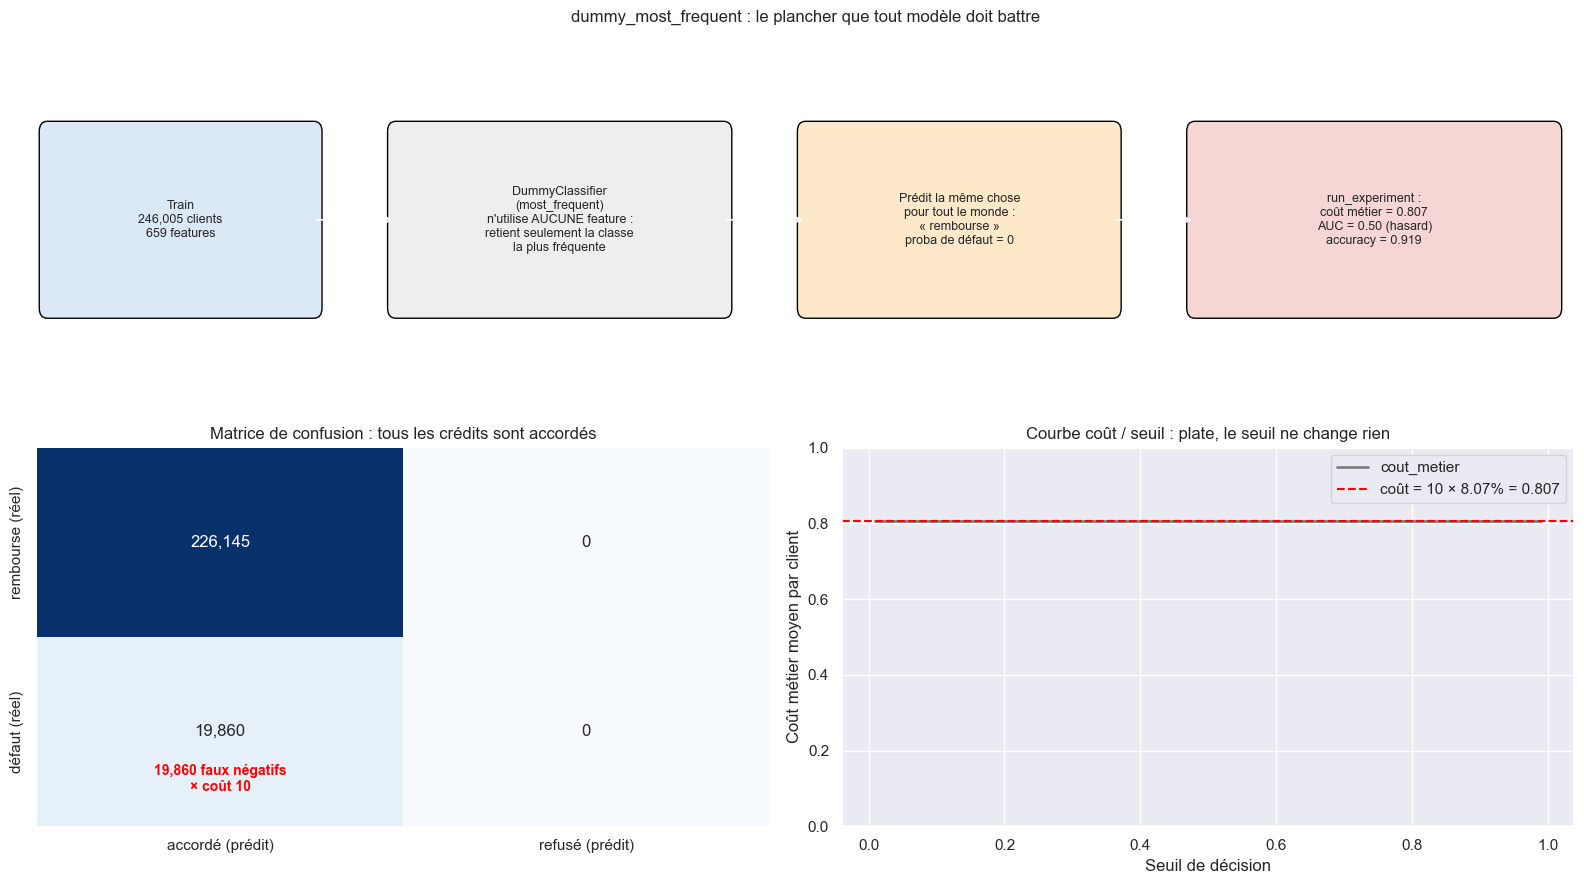

In [13]:
# -------------------------- Représentation graphique du modèle de référence (sans réentraînement) --------------------------
from matplotlib.patches import FancyBboxPatch

dummy_metrics = results["dummy_most_frequent"]  # métriques déjà calculées par run_experiment
dummy_costs = cost_curves["dummy_most_frequent"]  # courbe coût / seuil déjà calculée
n_good, n_bad = (y == 0).sum(), (y == 1).sum()

fig = plt.figure(figsize=(16, 9))

# ---- Figure 1 (haut) : schéma de ce que fait le Dummy ----
ax = fig.add_subplot(2, 1, 1)
ax.set_xlim(0, 15)
ax.set_ylim(0, 3)
ax.axis("off")


def box(x, y_, w, h, text, color):
    ax.add_patch(FancyBboxPatch((x, y_), w, h, boxstyle="round,pad=0.08", fc=color, ec="black"))
    ax.text(x + w / 2, y_ + h / 2, text, ha="center", va="center", fontsize=9)


def arrow(x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->", lw=1.2))


box(0.1, 0.8, 2.6, 1.4, f"Train\n{len(y):,} clients\n{X.shape[1]} features", "#dbe9f6")
box(3.5, 0.8, 3.2, 1.4, "DummyClassifier\n(most_frequent)\nn'utilise AUCUNE feature :\nretient seulement la classe\nla plus fréquente", "#eeeeee")
box(7.5, 0.8, 3.0, 1.4, "Prédit la même chose\npour tout le monde :\n« rembourse »\nproba de défaut = 0", "#fde9c9")
box(11.3, 0.8, 3.5, 1.4, f"run_experiment :\ncoût métier = {dummy_metrics['average_test_business_cost']:.3f}\nAUC = {dummy_metrics['average_test_roc_auc']:.2f} (hasard)\naccuracy = {dummy_metrics['average_test_accuracy']:.3f}", "#f6d5d5")
for x1, x2 in [(2.7, 3.5), (6.7, 7.5), (10.5, 11.3)]:
    arrow(x1, 1.5, x2, 1.5)
ax.set_title("dummy_most_frequent : le plancher que tout modèle doit battre", fontsize=12)

# ---- Figure 2 (bas gauche) : ses décisions sur les clients réels ----
ax2 = fig.add_subplot(2, 2, 3)
confusion = pd.DataFrame(
    [[n_good, 0], [n_bad, 0]],
    index=["rembourse (réel)", "défaut (réel)"],
    columns=["accordé (prédit)", "refusé (prédit)"],
)
sns.heatmap(confusion, annot=True, fmt=",", cmap="Blues", cbar=False, ax=ax2)
ax2.text(0.5, 1.75, f"{n_bad:,} faux négatifs\n× coût 10", ha="center", va="center", color="red", fontsize=10, weight="bold")
ax2.set_title("Matrice de confusion : tous les crédits sont accordés")

# ---- Figure 3 (bas droite) : coût métier selon le seuil ----
ax3 = fig.add_subplot(2, 2, 4)
dummy_costs.plot(ax=ax3, color="grey", lw=2)
ax3.axhline(dummy_metrics["average_test_business_cost"], color="red", ls="--",
            label=f"coût = 10 × {n_bad / len(y):.2%} = {dummy_metrics['average_test_business_cost']:.3f}")
ax3.set_ylim(0, 1)
ax3.set_xlabel("Seuil de décision")
ax3.set_ylabel("Coût métier moyen par client")
ax3.set_title("Courbe coût / seuil : plate, le seuil ne change rien")
ax3.legend()

plt.tight_layout()
plt.show()


In [ ]:
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    recall_score,
    roc_auc_score,
)

# Entraînement du modèle de référence
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)

# Prédictions sur le jeu de validation
y_pred = dummy.predict(X_test)
y_proba = dummy.predict_proba(X_test)[:, 1]

# Création des graphiques
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 1. Matrice de confusion
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Sans défaut (0)", "Défaut (1)"],
    cmap="Blues",
    values_format="d",
    ax=axes[0],
)
axes[0].set_title("Matrice de confusion — DummyClassifier")

# 2. Courbe ROC
RocCurveDisplay.from_predictions(
    y_test,
    y_proba,
    ax=axes[1],
    name="DummyClassifier",
)
axes[1].plot([0, 1], [0, 1], "k--", label="Hasard (AUC = 0,50)")
axes[1].set_title("Courbe ROC — DummyClassifier")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

# Résumé des performances
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, y_proba):.4f}")

## 5. Modèles simples : régression logistique et forêt aléatoire

**Régression logistique.** Modèle linéaire, rapide et interprétable : c'est la référence historique du scoring crédit. Elle exige :
- des données **sans valeurs manquantes** : imputation par la **médiane**, robuste aux valeurs extrêmes ;
- des variables **à la même échelle** : `StandardScaler`, sinon la régularisation pénalise injustement les variables à petites valeurs.

Ces étapes sont mises dans un **`Pipeline`** : la médiane et la moyenne sont recalculées sur les plis d'entraînement **uniquement**, sans fuite d'information du pli de validation.

**Forêt aléatoire.** Ensemble d'arbres de décision construits sur des sous-échantillons ; elle capte les **non-linéarités** et accepte les valeurs manquantes (scikit-learn ≥ 1.4). Pour rester raisonnable sur 8 Go de RAM, on limite la profondeur (`max_depth=12`) et chaque arbre voit 30 % des lignes (`max_samples=0.3`).

**Déséquilibre** : `class_weight="balanced"` donne à chaque défaut un poids d'environ 11,4 (ratio bons / mauvais clients), pour que l'algorithme ne se contente pas de prédire « bon client ».

In [8]:
_ = run_experiment(
    "logreg_balanced",
    make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LogisticRegression(class_weight="balanced", max_iter=1000, random_state=random_state),
    ),
    family="lineaire",
    imbalance="class_weight",
    description="Régression logistique, imputation médiane + standardisation, classes pondérées.",
)

logreg_balanced              AUC val 0.7692 (± 0.0020) | seuil 0.52 | coût 0.5130 (± 0.0036) | coût à 0,5 : 0.5140 | 46 s / pli


/var/folders/76/v3gkc48n6_z8w_gst8yvldm40000gn/T/ipykernel_31688/4070831951.py:32: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Arial.
  plt.tight_layout()
/Users/thibaultdautheville/Documents/VSCode/.conda/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


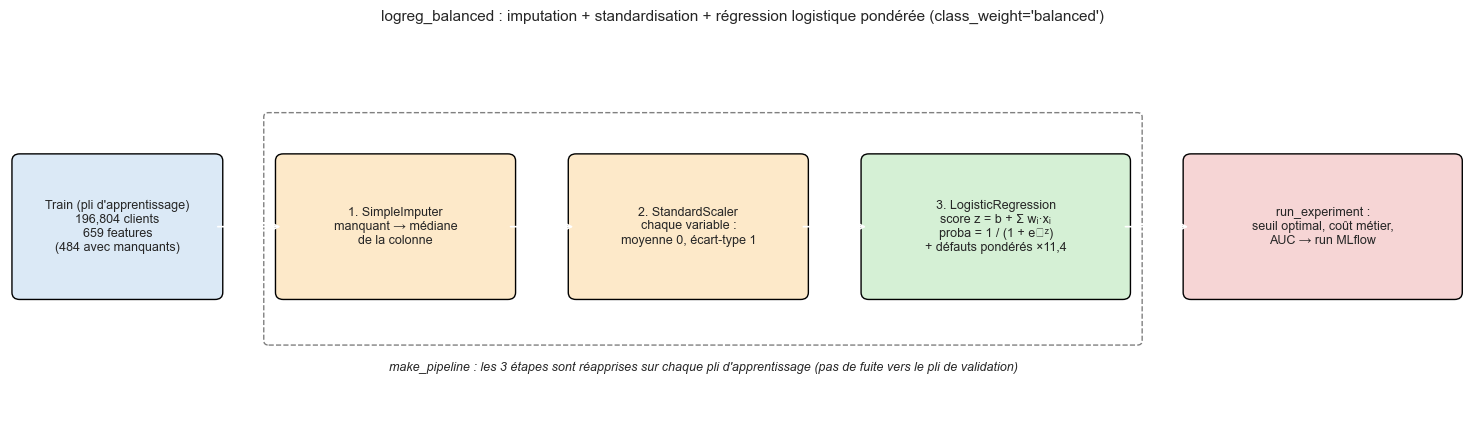

/var/folders/76/v3gkc48n6_z8w_gst8yvldm40000gn/T/ipykernel_31688/4070831951.py:60: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Arial.
  plt.tight_layout()
/Users/thibaultdautheville/Documents/VSCode/.conda/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


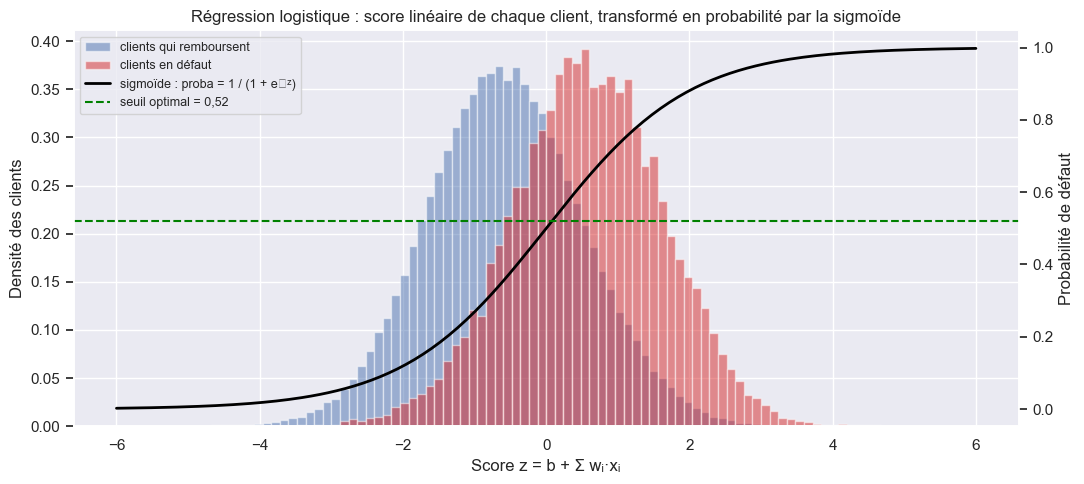

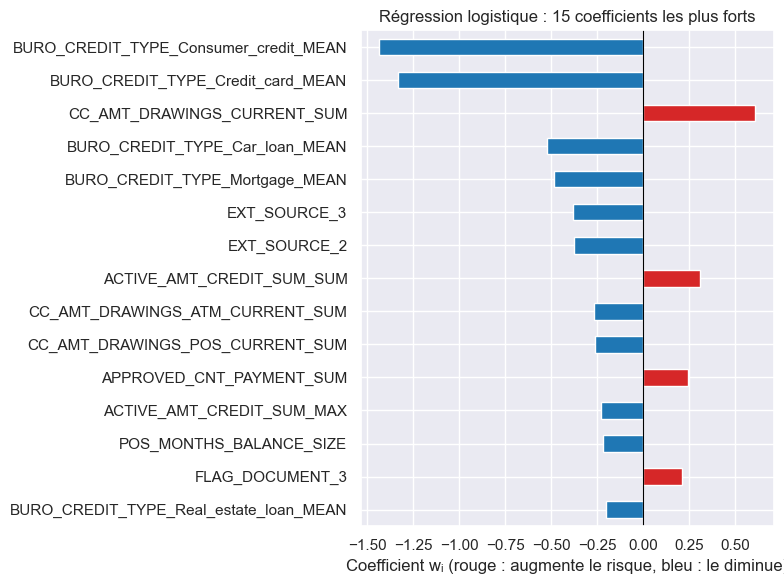

In [10]:
# -------------------------- Représentation graphique de la régression logistique --------------------------
from matplotlib.patches import FancyBboxPatch

# ---- Figure 1 : schéma de ce que fait le code (un pipeline en 3 étapes) ----
fig, ax = plt.subplots(figsize=(15, 4.5))
ax.set_xlim(0, 15)
ax.set_ylim(0, 4.5)
ax.axis("off")


def box(x, y, w, h, text, color):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.08", fc=color, ec="black"))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=9)


def arrow(x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->", lw=1.2))


box(0.1, 1.5, 2.0, 1.5, f"Train (pli d'apprentissage)\n{X.shape[0] * 4 // 5:,} clients\n{X.shape[1]} features\n(484 avec manquants)", "#dbe9f6")
box(2.8, 1.5, 2.3, 1.5, "1. SimpleImputer\nmanquant → médiane\nde la colonne", "#fde9c9")
box(5.8, 1.5, 2.3, 1.5, "2. StandardScaler\nchaque variable :\nmoyenne 0, écart-type 1", "#fde9c9")
box(8.8, 1.5, 2.6, 1.5, "3. LogisticRegression\nscore z = b + Σ wᵢ·xᵢ\nproba = 1 / (1 + e⁻ᶻ)\n+ défauts pondérés ×11,4", "#d5f0d5")
box(12.1, 1.5, 2.7, 1.5, "run_experiment :\nseuil optimal, coût métier,\nAUC → run MLflow", "#f6d5d5")
for x1, x2 in [(2.1, 2.8), (5.1, 5.8), (8.1, 8.8), (11.4, 12.1)]:
    arrow(x1, 2.25, x2, 2.25)

ax.add_patch(FancyBboxPatch((2.65, 0.95), 8.9, 2.55, boxstyle="round,pad=0.05", fc="none", ec="grey", ls="--"))
ax.text(7.1, 0.6, "make_pipeline : les 3 étapes sont réapprises sur chaque pli d'apprentissage (pas de fuite vers le pli de validation)",
        ha="center", fontsize=9, style="italic")
ax.set_title("logreg_balanced : imputation + standardisation + régression logistique pondérée (class_weight='balanced')", fontsize=11)
plt.tight_layout()
plt.show()

# ---- Entraînement du pipeline sur tout le train (environ 30 s) ----
logreg = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(class_weight="balanced", max_iter=1000, random_state=random_state),
).fit(X, y)

# ---- Figure 2 : de la somme pondérée à la probabilité (la sigmoïde) ----
scores_z = logreg.decision_function(X)  # z = b + Σ wᵢ·xᵢ pour chaque client
z_grid = np.linspace(-6, 6, 200)

fig, ax1 = plt.subplots(figsize=(11, 5))
ax1.hist(scores_z[y == 0], bins=100, range=(-6, 6), density=True, alpha=0.5, label="clients qui remboursent")
ax1.hist(scores_z[y == 1], bins=100, range=(-6, 6), density=True, alpha=0.5, color="tab:red", label="clients en défaut")
ax1.set_xlabel("Score z = b + Σ wᵢ·xᵢ")
ax1.set_ylabel("Densité des clients")
ax2 = ax1.twinx()
ax2.plot(z_grid, 1 / (1 + np.exp(-z_grid)), color="black", lw=2, label="sigmoïde : proba = 1 / (1 + e⁻ᶻ)")
ax2.axhline(0.52, color="green", ls="--", label="seuil optimal = 0,52")
ax2.set_ylabel("Probabilité de défaut")
ax2.grid(False)
lines = ax1.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
labels = ax1.get_legend_handles_labels()[1] + ax2.get_legend_handles_labels()[1]
ax1.legend(lines, labels, loc="upper left", fontsize=9)
ax1.set_title("Régression logistique : score linéaire de chaque client, transformé en probabilité par la sigmoïde")
plt.tight_layout()
plt.show()

# ---- Figure 3 : les 15 coefficients les plus forts (variables standardisées, donc comparables) ----
coefficients = pd.Series(logreg[-1].coef_[0], index=X.columns)
top = coefficients.reindex(coefficients.abs().sort_values().tail(15).index)
top.plot.barh(figsize=(8, 6), color=np.where(top > 0, "tab:red", "tab:blue"))
plt.axvline(0, color="black", lw=0.8)
plt.xlabel("Coefficient wᵢ (rouge : augmente le risque, bleu : le diminue)")
plt.title("Régression logistique : 15 coefficients les plus forts")
plt.tight_layout()
plt.show()


/var/folders/76/v3gkc48n6_z8w_gst8yvldm40000gn/T/ipykernel_31688/2283843766.py:32: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Arial.
  plt.tight_layout()
/Users/thibaultdautheville/Documents/VSCode/.conda/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


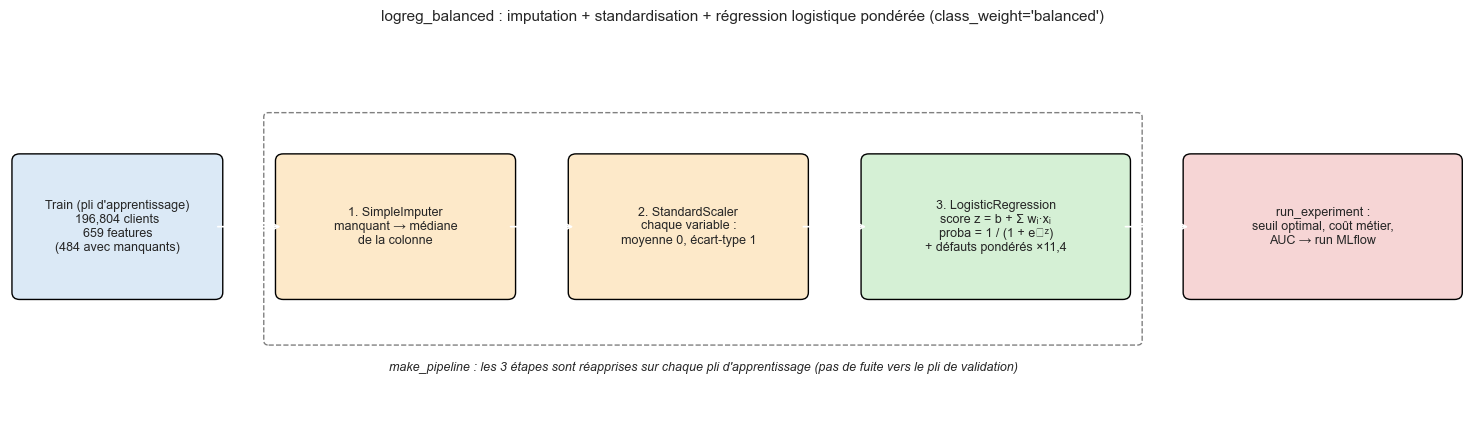

/var/folders/76/v3gkc48n6_z8w_gst8yvldm40000gn/T/ipykernel_31688/2283843766.py:44: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Arial.
  plt.tight_layout()


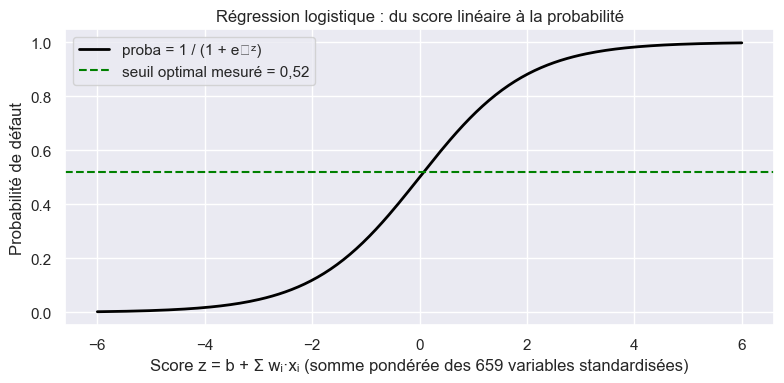

In [11]:
# -------------------------- Représentation graphique de la régression logistique (sans entraînement) --------------------------
from matplotlib.patches import FancyBboxPatch

# ---- Figure 1 : schéma du pipeline ----
fig, ax = plt.subplots(figsize=(15, 4.5))
ax.set_xlim(0, 15)
ax.set_ylim(0, 4.5)
ax.axis("off")


def box(x, y, w, h, text, color):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.08", fc=color, ec="black"))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=9)


def arrow(x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->", lw=1.2))


box(0.1, 1.5, 2.0, 1.5, f"Train (pli d'apprentissage)\n{X.shape[0] * 4 // 5:,} clients\n{X.shape[1]} features\n(484 avec manquants)", "#dbe9f6")
box(2.8, 1.5, 2.3, 1.5, "1. SimpleImputer\nmanquant → médiane\nde la colonne", "#fde9c9")
box(5.8, 1.5, 2.3, 1.5, "2. StandardScaler\nchaque variable :\nmoyenne 0, écart-type 1", "#fde9c9")
box(8.8, 1.5, 2.6, 1.5, "3. LogisticRegression\nscore z = b + Σ wᵢ·xᵢ\nproba = 1 / (1 + e⁻ᶻ)\n+ défauts pondérés ×11,4", "#d5f0d5")
box(12.1, 1.5, 2.7, 1.5, "run_experiment :\nseuil optimal, coût métier,\nAUC → run MLflow", "#f6d5d5")
for x1, x2 in [(2.1, 2.8), (5.1, 5.8), (8.1, 8.8), (11.4, 12.1)]:
    arrow(x1, 2.25, x2, 2.25)

ax.add_patch(FancyBboxPatch((2.65, 0.95), 8.9, 2.55, boxstyle="round,pad=0.05", fc="none", ec="grey", ls="--"))
ax.text(7.1, 0.6, "make_pipeline : les 3 étapes sont réapprises sur chaque pli d'apprentissage (pas de fuite vers le pli de validation)",
        ha="center", fontsize=9, style="italic")
ax.set_title("logreg_balanced : imputation + standardisation + régression logistique pondérée (class_weight='balanced')", fontsize=11)
plt.tight_layout()
plt.show()

# ---- Figure 2 : la sigmoïde, qui transforme le score z en probabilité ----
z_grid = np.linspace(-6, 6, 200)
plt.figure(figsize=(8, 4))
plt.plot(z_grid, 1 / (1 + np.exp(-z_grid)), color="black", lw=2, label="proba = 1 / (1 + e⁻ᶻ)")
plt.axhline(0.52, color="green", ls="--", label="seuil optimal mesuré = 0,52")
plt.xlabel("Score z = b + Σ wᵢ·xᵢ (somme pondérée des 659 variables standardisées)")
plt.ylabel("Probabilité de défaut")
plt.title("Régression logistique : du score linéaire à la probabilité")
plt.legend()
plt.tight_layout()
plt.show()


In [9]:
_ = run_experiment(
    "random_forest_balanced",
    RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        max_samples=0.3,
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=random_state,
    ),
    family="foret",
    imbalance="class_weight",
    description="Forêt aléatoire (200 arbres, profondeur 12, 30 % des lignes par arbre), classes pondérées.",
)

random_forest_balanced       AUC val 0.7367 (± 0.0033) | seuil 0.35 | coût 0.5599 (± 0.0044) | coût à 0,5 : 0.6467 | 27 s / pli


/var/folders/76/v3gkc48n6_z8w_gst8yvldm40000gn/T/ipykernel_31688/3306134402.py:62: UserWarning: Glyph 8942 (\N{VERTICAL ELLIPSIS}) missing from font(s) Arial.
  plt.tight_layout()
/Users/thibaultdautheville/Documents/VSCode/.conda/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8942 (\N{VERTICAL ELLIPSIS}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


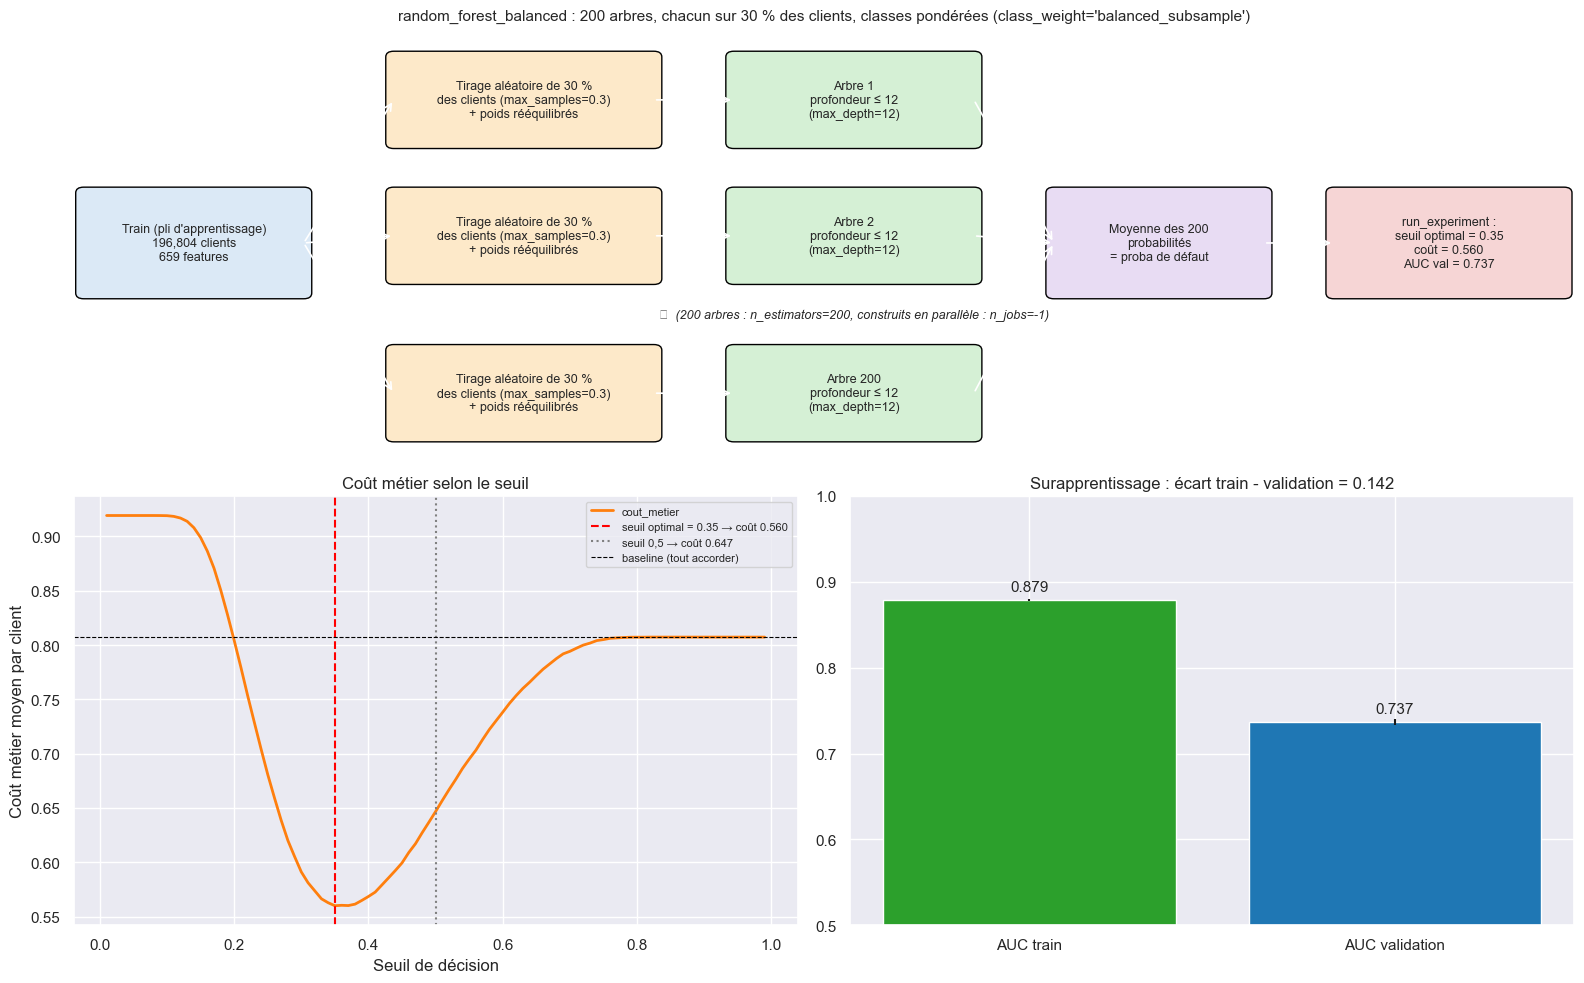

In [14]:
# -------------------------- Représentation graphique de la forêt aléatoire (sans réentraînement) --------------------------
from matplotlib.patches import FancyBboxPatch

rf_metrics = results["random_forest_balanced"]  # métriques déjà calculées par run_experiment
rf_costs = cost_curves["random_forest_balanced"]  # courbe coût / seuil déjà calculée

fig = plt.figure(figsize=(16, 10))

# ---- Figure 1 (haut) : schéma de ce que fait le code ----
ax = fig.add_subplot(2, 1, 1)
ax.set_xlim(0, 15)
ax.set_ylim(0, 6)
ax.axis("off")


def box(x, y_, w, h, text, color):
    ax.add_patch(FancyBboxPatch((x, y_), w, h, boxstyle="round,pad=0.08", fc=color, ec="black"))
    ax.text(x + w / 2, y_ + h / 2, text, ha="center", va="center", fontsize=9)


def arrow(x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->", lw=1.2))


box(0.1, 2.3, 2.2, 1.4, f"Train (pli d'apprentissage)\n{X.shape[0] * 4 // 5:,} clients\n{X.shape[1]} features", "#dbe9f6")
for y_pos, label in [(4.4, "Arbre 1"), (2.5, "Arbre 2"), (0.3, "Arbre 200")]:
    box(3.2, y_pos, 2.6, 1.2, "Tirage aléatoire de 30 %\ndes clients (max_samples=0.3)\n+ poids rééquilibrés", "#fde9c9")
    box(6.6, y_pos, 2.4, 1.2, f"{label}\nprofondeur ≤ 12\n(max_depth=12)", "#d5f0d5")
    arrow(2.3, 3.0, 3.2, y_pos + 0.6)
    arrow(5.8, y_pos + 0.6, 6.6, y_pos + 0.6)
    arrow(9.0, y_pos + 0.6, 9.8, 3.0)
ax.text(7.8, 1.95, "⋮  (200 arbres : n_estimators=200, construits en parallèle : n_jobs=-1)", ha="center", fontsize=9, style="italic")
box(9.8, 2.3, 2.1, 1.4, "Moyenne des 200\nprobabilités\n= proba de défaut", "#e8dcf3")
box(12.6, 2.3, 2.3, 1.4,
    f"run_experiment :\nseuil optimal = {rf_metrics['best_threshold']:.2f}\ncoût = {rf_metrics['average_test_business_cost']:.3f}\nAUC val = {rf_metrics['average_test_roc_auc']:.3f}",
    "#f6d5d5")
arrow(11.9, 3.0, 12.6, 3.0)
ax.set_title("random_forest_balanced : 200 arbres, chacun sur 30 % des clients, classes pondérées (class_weight='balanced_subsample')", fontsize=11)

# ---- Figure 2 (bas gauche) : coût métier selon le seuil ----
ax2 = fig.add_subplot(2, 2, 3)
rf_costs.plot(ax=ax2, color="tab:orange", lw=2)
ax2.axvline(rf_metrics["best_threshold"], color="red", ls="--",
            label=f"seuil optimal = {rf_metrics['best_threshold']:.2f} → coût {rf_metrics['average_test_business_cost']:.3f}")
ax2.axvline(0.5, color="grey", ls=":", label=f"seuil 0,5 → coût {rf_metrics['business_cost_threshold_05']:.3f}")
ax2.axhline(results["dummy_most_frequent"]["average_test_business_cost"], color="black", ls="--", lw=0.8, label="baseline (tout accorder)")
ax2.set_xlabel("Seuil de décision")
ax2.set_ylabel("Coût métier moyen par client")
ax2.set_title("Coût métier selon le seuil")
ax2.legend(fontsize=8)

# ---- Figure 3 (bas droite) : surapprentissage, AUC train vs validation ----
ax3 = fig.add_subplot(2, 2, 4)
auc = pd.Series({"AUC train": rf_metrics["average_train_roc_auc"], "AUC validation": rf_metrics["average_test_roc_auc"]})
auc_std = [rf_metrics["train_roc_auc_std"], rf_metrics["test_roc_auc_std"]]
ax3.bar(auc.index, auc.values, yerr=auc_std, color=["tab:green", "tab:blue"])
for i, v in enumerate(auc.values):
    ax3.text(i, v + 0.01, f"{v:.3f}", ha="center", fontsize=11)
ax3.set_ylim(0.5, 1)
ax3.set_title(f"Surapprentissage : écart train - validation = {rf_metrics['overfit_gap_roc_auc']:.3f}")

plt.tight_layout()
plt.show()


/var/folders/76/v3gkc48n6_z8w_gst8yvldm40000gn/T/ipykernel_31688/1400029095.py:43: UserWarning: Glyph 8942 (\N{VERTICAL ELLIPSIS}) missing from font(s) Arial.
  plt.tight_layout()


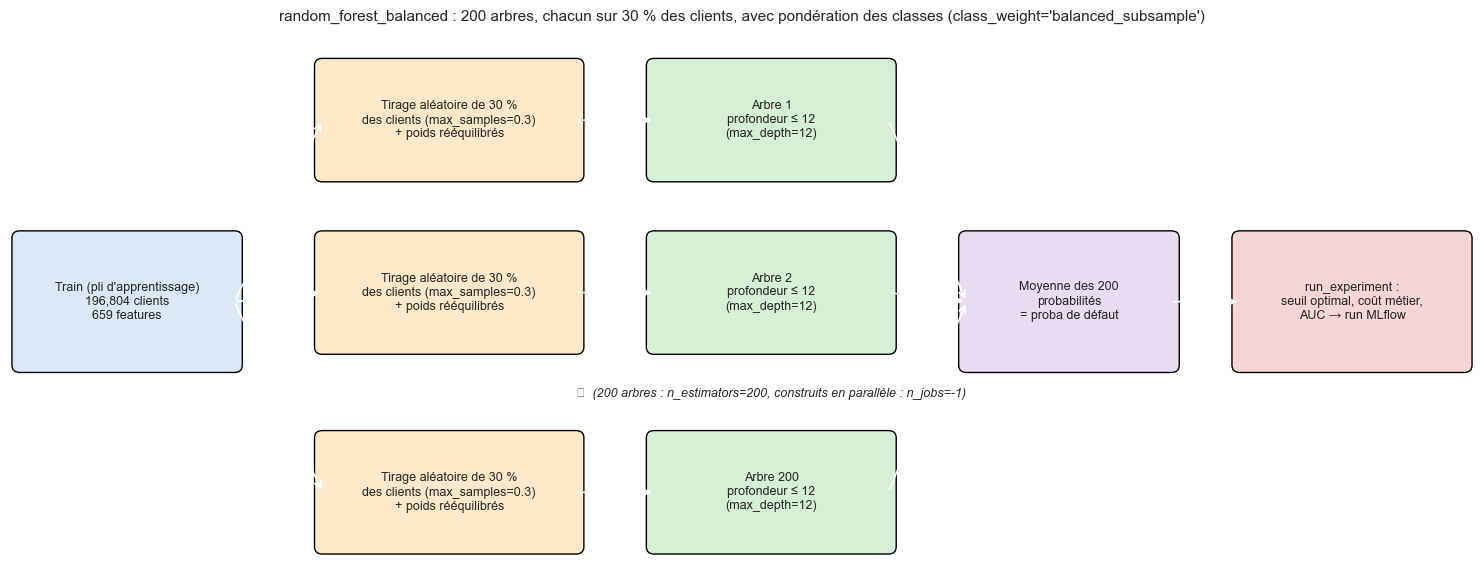

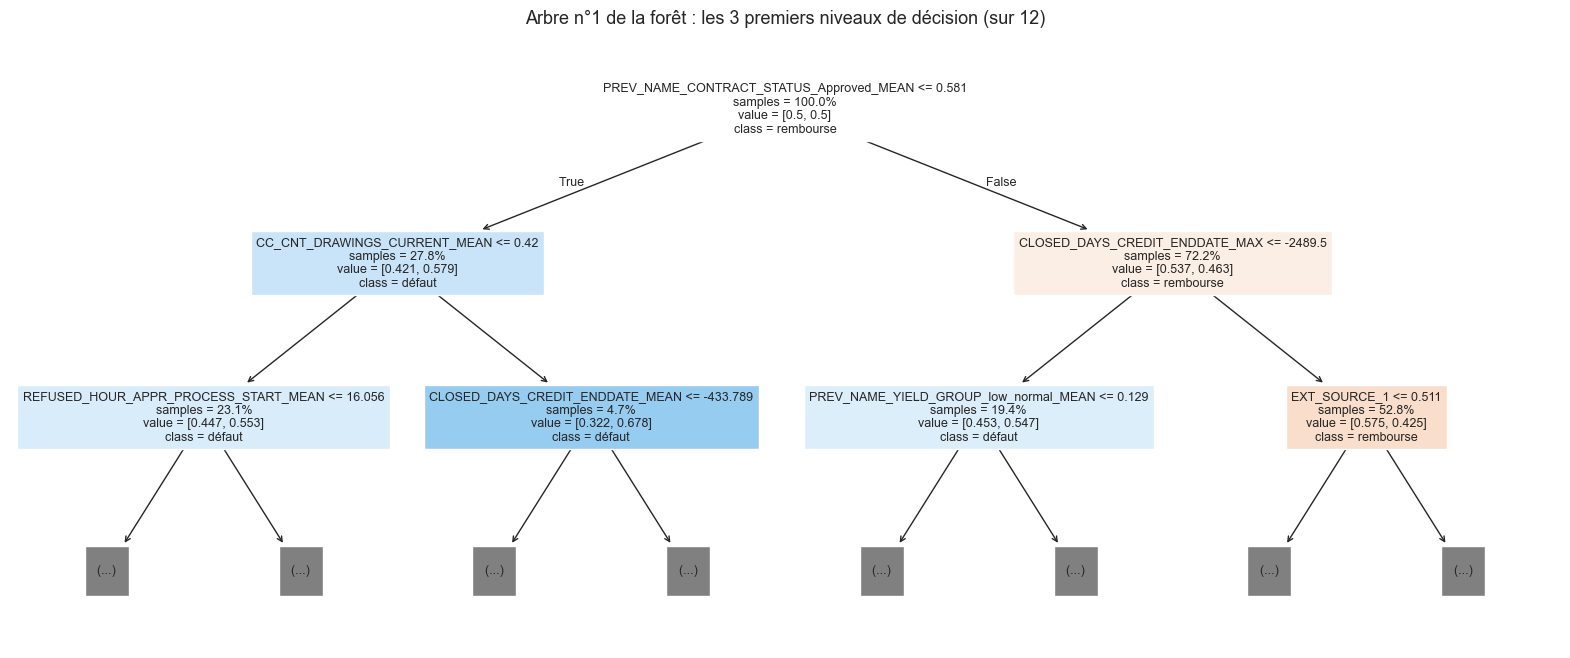

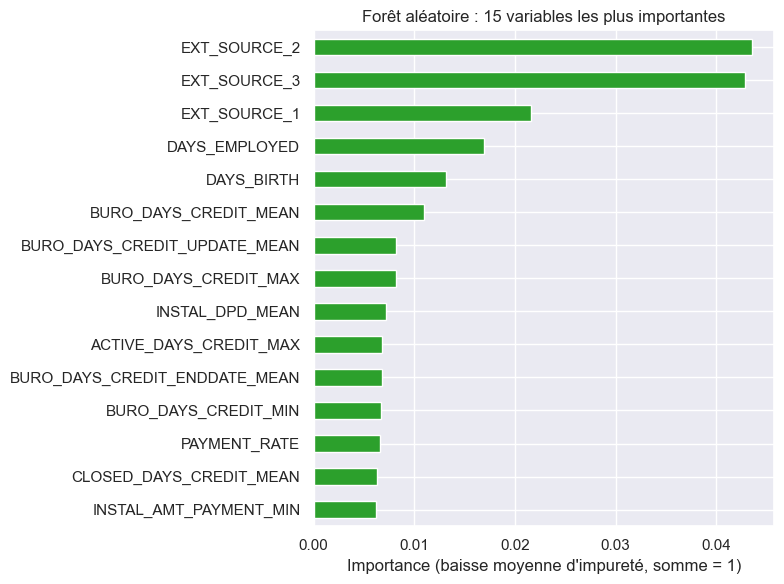

In [15]:
# -------------------------- Représentation graphique de la forêt aléatoire --------------------------
from matplotlib.patches import FancyBboxPatch
from sklearn.tree import plot_tree

# ---- Figure 1 : schéma de ce que fait le code ----
fig, ax = plt.subplots(figsize=(15, 6))
ax.set_xlim(0, 15)
ax.set_ylim(0, 6)
ax.axis("off")


def box(x, y, w, h, text, color):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.08", fc=color, ec="black"))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=9)


def arrow(x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->", lw=1.2))


# Données d'entrée
box(0.1, 2.3, 2.2, 1.4, f"Train (pli d'apprentissage)\n{X.shape[0] * 4 // 5:,} clients\n{X.shape[1]} features", "#dbe9f6")

# 3 arbres représentatifs sur 200
for i, (y_pos, label) in enumerate([(4.4, "Arbre 1"), (2.5, "Arbre 2"), (0.3, "Arbre 200")]):
    box(3.2, y_pos, 2.6, 1.2, "Tirage aléatoire de 30 %\ndes clients (max_samples=0.3)\n+ poids rééquilibrés", "#fde9c9")
    box(6.6, y_pos, 2.4, 1.2, f"{label}\nprofondeur ≤ 12\n(max_depth=12)", "#d5f0d5")
    arrow(2.3, 3.0, 3.2, y_pos + 0.6)
    arrow(5.8, y_pos + 0.6, 6.6, y_pos + 0.6)
    arrow(9.0, y_pos + 0.6, 9.8, 3.0)
ax.text(7.8, 1.95, "⋮  (200 arbres : n_estimators=200, construits en parallèle : n_jobs=-1)", ha="center", fontsize=9, style="italic")

# Agrégation, seuil, coût
box(9.8, 2.3, 2.1, 1.4, "Moyenne des 200\nprobabilités\n= proba de défaut", "#e8dcf3")
box(12.6, 2.3, 2.3, 1.4, "run_experiment :\nseuil optimal, coût métier,\nAUC → run MLflow", "#f6d5d5")
arrow(11.9, 3.0, 12.6, 3.0)

ax.set_title(
    "random_forest_balanced : 200 arbres, chacun sur 30 % des clients, avec pondération des classes "
    "(class_weight='balanced_subsample')",
    fontsize=11,
)
plt.tight_layout()
plt.show()

# ---- Figure 2 : un vrai arbre de la forêt (3 premiers niveaux sur 12) ----
forest = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    max_samples=0.3,
    class_weight="balanced_subsample",
    n_jobs=-1,
    random_state=random_state,
).fit(X, y)

fig, ax = plt.subplots(figsize=(20, 8))
plot_tree(
    forest.estimators_[0],
    max_depth=2,
    feature_names=X.columns,
    class_names=["rembourse", "défaut"],
    filled=True,
    impurity=False,
    proportion=True,
    fontsize=9,
    ax=ax,
)
ax.set_title("Arbre n°1 de la forêt : les 3 premiers niveaux de décision (sur 12)", fontsize=13)
plt.show()

# ---- Figure 3 : les variables les plus utilisées par l'ensemble des 200 arbres ----
importances = pd.Series(forest.feature_importances_, index=X.columns).sort_values().tail(15)
importances.plot.barh(figsize=(8, 6), color="tab:green")
plt.xlabel("Importance (baisse moyenne d'impureté, somme = 1)")
plt.title("Forêt aléatoire : 15 variables les plus importantes")
plt.tight_layout()
plt.show()


## 6. Boosting : LightGBM et XGBoost

Le **gradient boosting** construit des arbres **successivement**, chacun corrigeant les erreurs des précédents. C'est en général la famille la plus performante sur des données tabulaires, et c'est celle du kernel Kaggle dont nos features sont issues. LightGBM et XGBoost gèrent nativement les valeurs manquantes.

**Trois façons de traiter le déséquilibre, testées sur LightGBM**
1. **Aucune** : le modèle apprend sur les données telles quelles.
2. **`class_weight="balanced"`** : on pondère les erreurs sur les défauts.
3. **SMOTE** : on crée des défauts **synthétiques** par interpolation entre voisins proches. SMOTE ne tolère pas les valeurs manquantes : il faut imputer avant. Le pipeline `imblearn` applique SMOTE **uniquement pendant l'entraînement**, sur les plis d'apprentissage ; le pli de validation garde la vraie distribution, sinon les scores seraient faussés.

Pour XGBoost, l'équivalent de `class_weight` est **`scale_pos_weight`** = nombre de bons / nombre de mauvais clients.

In [7]:
_ = run_experiment(
    "lightgbm_sans_ponderation",
    LGBMClassifier(random_state=random_state, n_jobs=-1, verbose=-1),
    family="boosting",
    imbalance="aucune",
    description="LightGBM, hyperparamètres par défaut, sans traitement du déséquilibre.",
)

_ = run_experiment(
    "lightgbm_balanced",
    LGBMClassifier(class_weight="balanced", random_state=random_state, n_jobs=-1, verbose=-1),
    family="boosting",
    imbalance="class_weight",
    description="LightGBM, hyperparamètres par défaut, classes pondérées.",
)

lightgbm_sans_ponderation    AUC val 0.7802 (± 0.0010) | seuil 0.08 | coût 0.4974 (± 0.0017) | coût à 0,5 : 0.7787 | 8 s / pli
lightgbm_balanced            AUC val 0.7818 (± 0.0014) | seuil 0.48 | coût 0.4966 (± 0.0039) | coût à 0,5 : 0.4971 | 9 s / pli


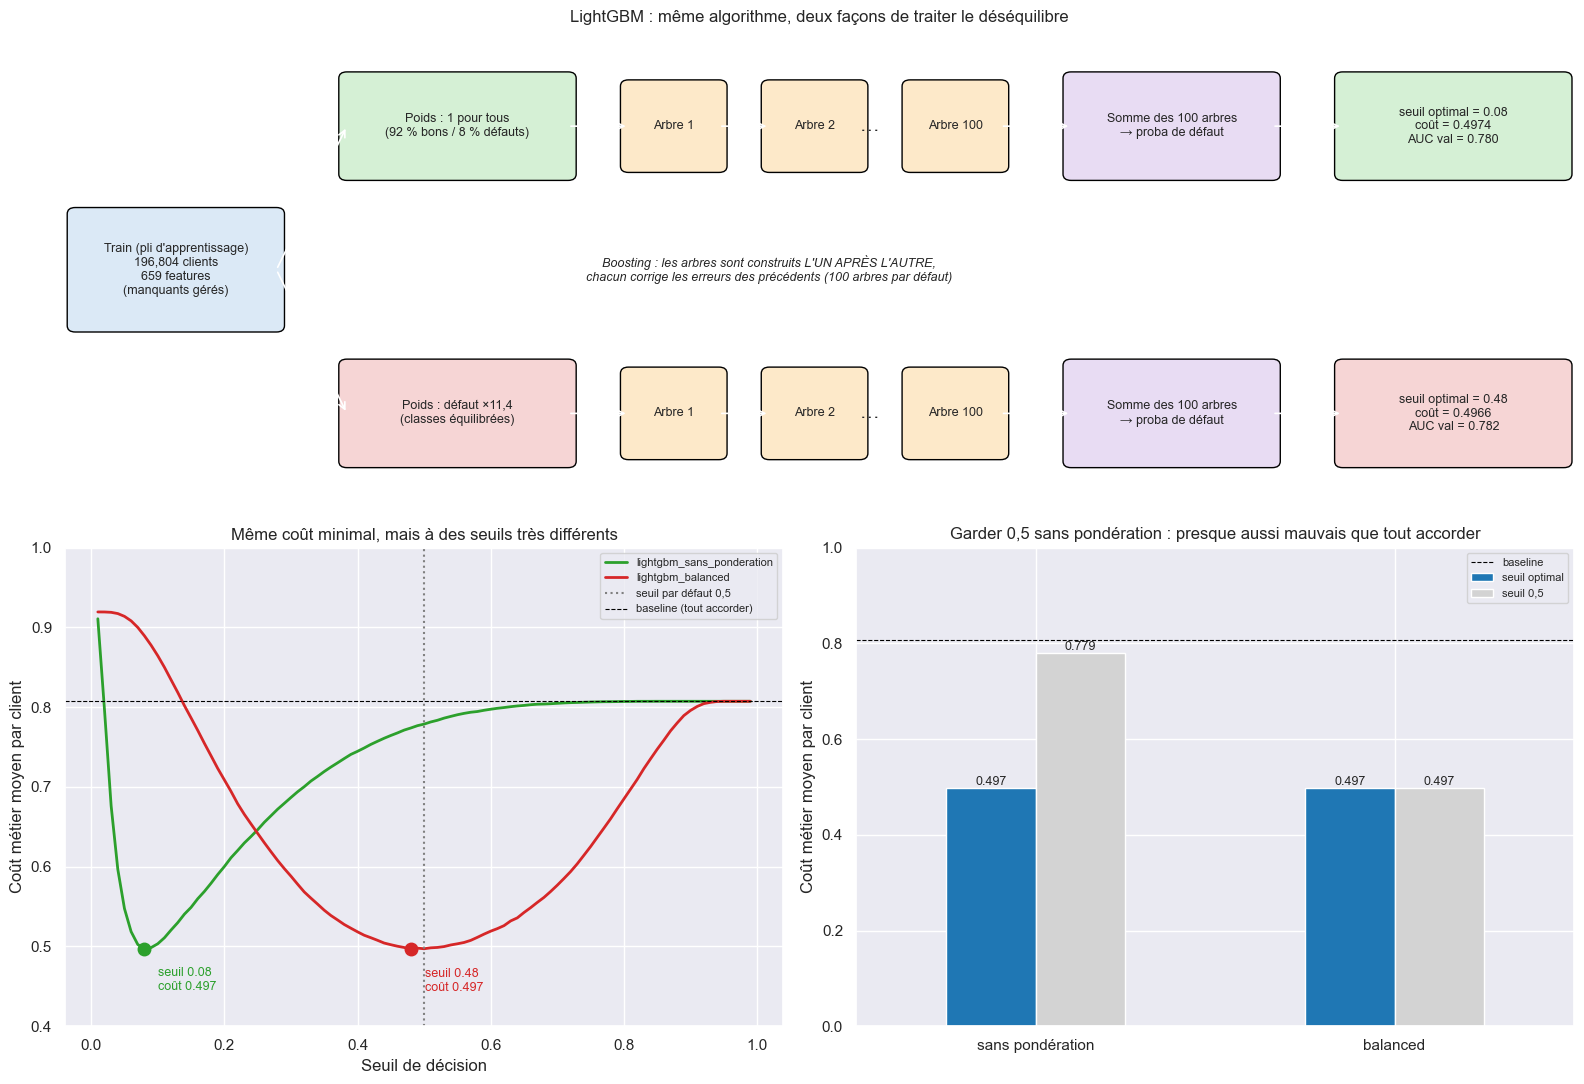

In [16]:
# -------------------------- Représentation graphique des deux LightGBM (sans réentraînement) --------------------------
from matplotlib.patches import FancyBboxPatch

models = {"lightgbm_sans_ponderation": "tab:green", "lightgbm_balanced": "tab:red"}
m_none, m_bal = results["lightgbm_sans_ponderation"], results["lightgbm_balanced"]

fig = plt.figure(figsize=(16, 11))

# ---- Figure 1 (haut) : schéma du boosting, avec et sans pondération ----
ax = fig.add_subplot(2, 1, 1)
ax.set_xlim(0, 15)
ax.set_ylim(0, 6)
ax.axis("off")


def box(x, y_, w, h, text, color):
    ax.add_patch(FancyBboxPatch((x, y_), w, h, boxstyle="round,pad=0.08", fc=color, ec="black"))
    ax.text(x + w / 2, y_ + h / 2, text, ha="center", va="center", fontsize=9)


def arrow(x1, y1, x2, y2, label=""):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->", lw=1.2))
    if label:
        ax.text((x1 + x2) / 2, (y1 + y2) / 2 + 0.15, label, ha="center", fontsize=8, style="italic")


box(0.1, 2.3, 2.0, 1.4, f"Train (pli d'apprentissage)\n{X.shape[0] * 4 // 5:,} clients\n{X.shape[1]} features\n(manquants gérés)", "#dbe9f6")

for y_pos, name, weight_text, color in [
    (4.2, "lightgbm_sans_ponderation", "Poids : 1 pour tous\n(92 % bons / 8 % défauts)", "#d5f0d5"),
    (0.6, "lightgbm_balanced", "Poids : défaut ×11,4\n(classes équilibrées)", "#f6d5d5"),
]:
    m = results[name]
    box(2.8, y_pos, 2.2, 1.2, weight_text, color)
    arrow(2.1, 3.0, 2.8, y_pos + 0.6)
    # 100 arbres construits l'un après l'autre : chacun corrige les erreurs des précédents
    for k, x in enumerate([5.6, 7.0, 8.4]):
        box(x, y_pos + 0.1, 0.9, 1.0, ["Arbre 1", "Arbre 2", "Arbre 100"][k], "#fde9c9")
    arrow(5.0, y_pos + 0.6, 5.6, y_pos + 0.6)
    arrow(6.5, y_pos + 0.6, 7.0, y_pos + 0.6)
    ax.text(8.0, y_pos + 0.6, "…", ha="center", va="center", fontsize=14)
    box(10.0, y_pos, 2.0, 1.2, "Somme des 100 arbres\n→ proba de défaut", "#e8dcf3")
    arrow(9.3, y_pos + 0.6, 10.0, y_pos + 0.6)
    box(12.7, y_pos, 2.2, 1.2,
        f"seuil optimal = {m['best_threshold']:.2f}\ncoût = {m['average_test_business_cost']:.4f}\nAUC val = {m['average_test_roc_auc']:.3f}",
        color)
    arrow(12.0, y_pos + 0.6, 12.7, y_pos + 0.6)

ax.text(7.0, 3.0, "Boosting : les arbres sont construits L'UN APRÈS L'AUTRE,\nchacun corrige les erreurs des précédents (100 arbres par défaut)",
        ha="center", va="center", fontsize=9, style="italic")
ax.set_title("LightGBM : même algorithme, deux façons de traiter le déséquilibre", fontsize=12)

# ---- Figure 2 (bas gauche) : les deux courbes coût / seuil ----
ax2 = fig.add_subplot(2, 2, 3)
for name, color in models.items():
    m = results[name]
    cost_curves[name].plot(ax=ax2, color=color, lw=2, label=name)
    ax2.plot(m["best_threshold"], cost_curves[name].min(), "o", color=color, markersize=9)
    ax2.annotate(f"seuil {m['best_threshold']:.2f}\ncoût {cost_curves[name].min():.3f}",
                 (m["best_threshold"], cost_curves[name].min()), textcoords="offset points", xytext=(10, -30), color=color, fontsize=9)
ax2.axvline(0.5, color="grey", ls=":", label="seuil par défaut 0,5")
ax2.axhline(results["dummy_most_frequent"]["average_test_business_cost"], color="black", ls="--", lw=0.8, label="baseline (tout accorder)")
ax2.set_ylim(0.4, 1.0)
ax2.set_xlabel("Seuil de décision")
ax2.set_ylabel("Coût métier moyen par client")
ax2.set_title("Même coût minimal, mais à des seuils très différents")
ax2.legend(fontsize=8, loc="upper right")

# ---- Figure 3 (bas droite) : coût au seuil optimal vs au seuil 0,5 ----
ax3 = fig.add_subplot(2, 2, 4)
comparison_costs = pd.DataFrame(
    {
        "seuil optimal": [m_none["average_test_business_cost"], m_bal["average_test_business_cost"]],
        "seuil 0,5": [m_none["business_cost_threshold_05"], m_bal["business_cost_threshold_05"]],
    },
    index=["sans pondération", "balanced"],
)
comparison_costs.plot.bar(ax=ax3, color=["tab:blue", "lightgrey"], rot=0)
for container in ax3.containers:
    ax3.bar_label(container, fmt="%.3f", fontsize=9)
ax3.axhline(results["dummy_most_frequent"]["average_test_business_cost"], color="black", ls="--", lw=0.8, label="baseline")
ax3.set_ylim(0, 1)
ax3.set_ylabel("Coût métier moyen par client")
ax3.set_title("Garder 0,5 sans pondération : presque aussi mauvais que tout accorder")
ax3.legend(fontsize=8)

plt.tight_layout()
plt.show()


In [17]:
_ = run_experiment(
    "lightgbm_smote",
    make_imb_pipeline(
        SimpleImputer(strategy="median"),
        SMOTE(random_state=random_state),
        LGBMClassifier(random_state=random_state, n_jobs=-1, verbose=-1),
    ),
    family="boosting",
    imbalance="smote",
    description="LightGBM après imputation médiane et sur-échantillonnage SMOTE (dans les plis).",
)

python(35487) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


lightgbm_smote               AUC val 0.7745 (± 0.0018) | seuil 0.10 | coût 0.5104 (± 0.0046) | coût à 0,5 : 0.7903 | 59 s / pli


In [18]:
scale_pos_weight = (y == 0).sum() / (y == 1).sum()

_ = run_experiment(
    "xgboost_scale_pos_weight",
    XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        tree_method="hist",
        scale_pos_weight=scale_pos_weight,
        n_jobs=-1,
        random_state=random_state,
    ),
    family="boosting",
    imbalance="scale_pos_weight",
    description="XGBoost (300 arbres, learning rate 0,05, profondeur 6), scale_pos_weight = ratio bons / mauvais.",
)

xgboost_scale_pos_weight     AUC val 0.7802 (± 0.0012) | seuil 0.48 | coût 0.4982 (± 0.0029) | coût à 0,5 : 0.4996 | 37 s / pli


## 7. Réseau de neurones : MLP

Le **perceptron multicouche** (`MLPClassifier`) enchaîne des couches de neurones (ici 64 puis 32). Comme la régression logistique, il exige des données imputées et standardisées.

`MLPClassifier` n'a pas de paramètre `class_weight` : on rééquilibre donc les données avec un **sous-échantillonnage aléatoire** de la classe majoritaire (`RandomUnderSampler`), dans les plis d'entraînement uniquement. Lors d'un premier essai, SMOTE dégradait nettement le MLP (AUC ≈ 0,65 contre 0,75) : le réseau surapprenait les points synthétiques. `early_stopping=True` arrête l'apprentissage quand le score sur une part de validation interne cesse de progresser.

In [ ]:
_ = run_experiment(
    "mlp_undersampling",
    make_imb_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        RandomUnderSampler(random_state=random_state),
        MLPClassifier(hidden_layer_sizes=(64, 32), alpha=1e-2, early_stopping=True, random_state=random_state),
    ),
    family="reseau_neurones",
    imbalance="undersampling",
    description="MLP (64, 32), imputation + standardisation, sous-échantillonnage de la classe majoritaire.",
)

## 8. Comparaison des modèles

Le tableau est trié par **coût métier** (critère principal). L'AUC reste un indicateur de contrôle de la qualité de classement. L'accuracy est affichée pour rappel, mais elle n'est **pas** un critère de choix.

In [ ]:
comparison = pd.DataFrame(results).T
columns = {
    "famille": "famille",
    "desequilibre": "déséquilibre",
    "average_test_business_cost": "coût métier",
    "test_business_cost_std": "coût (écart-type)",
    "best_threshold": "seuil optimal",
    "business_cost_threshold_05": "coût au seuil 0,5",
    "average_test_roc_auc": "AUC val",
    "test_roc_auc_std": "AUC (écart-type)",
    "average_train_roc_auc": "AUC train",
    "overfit_gap_roc_auc": "écart train - val",
    "average_test_recall": "rappel",
    "average_test_precision": "précision",
    "average_test_f1": "F1",
    "average_test_accuracy": "accuracy",
    "average_fit_time_s": "temps / pli (s)",
}
comparison = comparison[list(columns)].rename(columns=columns).sort_values("coût métier")
numeric_columns = comparison.columns.drop(["famille", "déséquilibre"])
comparison[numeric_columns] = comparison[numeric_columns].astype(float).round(4)
comparison

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

plot_data = comparison.drop(index="dummy_most_frequent").sort_values("coût métier", ascending=False)
axes[0].barh(plot_data.index, plot_data["coût métier"], xerr=plot_data["coût (écart-type)"], color="tab:blue")
axes[0].axvline(comparison.loc["dummy_most_frequent", "coût métier"], color="red", linestyle="--", label="baseline (tout accorder)")
axes[0].set_xlabel("Coût métier moyen par client (plus bas = meilleur)")
axes[0].set_title("Coût métier au seuil optimal (moyenne ± écart-type sur 5 plis)")
axes[0].legend(loc="lower right")

for name, costs in cost_curves.items():
    if name != "dummy_most_frequent":
        costs.plot(ax=axes[1], label=name)
axes[1].axhline(comparison.loc["dummy_most_frequent", "coût métier"], color="red", linestyle="--")
axes[1].set_xlabel("Seuil de décision")
axes[1].set_ylabel("Coût métier moyen par client")
axes[1].set_title("Coût métier en fonction du seuil")
axes[1].set_ylim(0.4, 1.0)
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig(FIGURES_PATH / "03_1_comparaison_modeles.png", dpi=100)
plt.show()

## 9. Lecture des résultats

> Les commentaires ci-dessous s'appuient sur les résultats affichés plus haut ; ils sont à relire si le notebook est relancé avec d'autres paramètres.

**À compléter après exécution** : voir la cellule suivante pour un résumé automatique, puis le bilan.

In [ ]:
best = comparison.drop(index="dummy_most_frequent").iloc[0]
baseline_cost = comparison.loc["dummy_most_frequent", "coût métier"]
print(f"Meilleur modèle (coût métier) : {best.name}")
print(f"  coût {best['coût métier']:.4f} contre {baseline_cost:.4f} pour la baseline, soit {1 - best['coût métier'] / baseline_cost:.0%} d'économie")
print(f"  seuil optimal {best['seuil optimal']:.2f} | coût au seuil 0,5 : {best['coût au seuil 0,5']:.4f}")
print(f"  AUC val {best['AUC val']:.4f} | rappel {best['rappel']:.2%} | précision {best['précision']:.2%}")
print(f"\nModèles dont l'AUC de validation dépasse 0,82 (à vérifier : fuite de données ?) : {list(comparison.index[comparison['AUC val'] > 0.82]) or 'aucun'}")